In [14]:
import pandas as pd

df = pd.read_csv("../datasets/raw/Resume_dataset.csv")

print(df.head())
print(df.shape)
print(df.columns)
print(df.info())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate resumes:", df["Text"].duplicated().sum())
print("Total resumes:", len(df))
print("Unique resume texts:", df["Text"].nunique())
print("Repeated resume occurrences:", df["Text"].duplicated().sum())
duplicate_text = df[df["Text"].duplicated(keep=False)]

print(duplicate_text.head(10))
duplicate_text[["category", "job_title", "Text"]].head(20)

resume_counts = df["Text"].value_counts()

print(resume_counts.head(10))
most_repeated_resume = resume_counts.index[0]

print("Occurrences:", resume_counts.iloc[0])
print("Resume:")
print(most_repeated_resume)

same_resume = df[df["Text"] == most_repeated_resume]

print(same_resume[["category", "job_title"]].to_string(index=False))

resume_counts = df["Text"].value_counts()

print(resume_counts.head(10))
same_resume = df[df["Text"] == most_repeated_resume]

print(same_resume[["category", "job_title"]].to_string(index=False))
same_resume = df[df["Text"] == most_repeated_resume]

print(same_resume[["category", "job_title"]].to_string(index=False))


                             category                job_title  \
0  Java Developers/Architects Resumes           Java Developer   
1  Java Developers/Architects Resumes  Sr. Java/J2EE Developer   
2  Java Developers/Architects Resumes        Sr. iOS Developer   
3  Java Developers/Architects Resumes      Core Java Developer   
4  Java Developers/Architects Resumes        Android Developer   

                                                Text  
0  Flair for technology and willing to take chall...  
1  Senior Java Developer with around 7+ years of ...  
2  Overall 7 years of experience in design and de...  
3  7 + years of experience in Application Analysi...  
4  With approx 5 years of experience in IT sector...  
(9000, 3)
Index(['category', 'job_title', 'Text'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   category   9000 non-null   str  


In [18]:
resume_counts = df["Text"].value_counts()

most_repeated_resume = resume_counts.index[0]

same_resume = df[df["Text"] == most_repeated_resume]

print("Number of times this resume appears:", len(same_resume))
print()
print("Categories:")
print(same_resume["category"].unique())
print()
print("Job titles:")
print(same_resume["job_title"].unique())
print("Number of categories:", df["category"].nunique())
print(df["category"].value_counts())
print(df["category"].value_counts(normalize=True) * 100)

Number of times this resume appears: 27

Categories:
<StringArray>
['Recruiter Resumes']
Length: 1, dtype: str

Job titles:
<StringArray>
['Senior Web UI Developer',        'Web UI Developer',
           'Web Developer', 'Lead UI/Web Development']
Length: 4, dtype: str
Number of categories: 9
category
Java Developers/Architects Resumes                1000
Web Developer Resumes                             1000
SQL Developers Resumes                            1000
Business Analyst (BA) Resumes                     1000
Network and Systems Administrators Resumes        1000
Datawarehousing, ETL, Informatica Resumes         1000
Business Intelligence, Business Object Resumes    1000
Project Manager Resumes                           1000
Recruiter Resumes                                 1000
Name: count, dtype: int64
category
Java Developers/Architects Resumes                11.111111
Web Developer Resumes                             11.111111
SQL Developers Resumes                         

In [23]:
df["text_length"] = df["Text"].str.len()
print(df["text_length"].describe())
print(df.nsmallest(10, "text_length")[["category", "job_title", "text_length", "Text"]])



count     9000.000000
mean     11723.550444
std       6016.371245
min        595.000000
25%       7616.750000
50%      11168.000000
75%      14909.000000
max      61052.000000
Name: text_length, dtype: float64
                                            category  \
6335  Business Intelligence, Business Object Resumes   
5428       Datawarehousing, ETL, Informatica Resumes   
1959                           Web Developer Resumes   
5113       Datawarehousing, ETL, Informatica Resumes   
5279       Datawarehousing, ETL, Informatica Resumes   
5057       Datawarehousing, ETL, Informatica Resumes   
5284       Datawarehousing, ETL, Informatica Resumes   
5514       Datawarehousing, ETL, Informatica Resumes   
5690       Datawarehousing, ETL, Informatica Resumes   
5603       Datawarehousing, ETL, Informatica Resumes   

                                job_title  text_length  \
6335                              Support          595   
5428             I.T. Staffing contractor          658   

In [26]:
longest = df.nlargest(5, "text_length")

print(longest[["category", "job_title", "text_length"]].to_string(index=False))
shortest = df.nsmallest(5, "text_length")

print(shortest[["category", "job_title", "text_length"]].to_string(index=False))

print("Empty/whitespace resumes:", df["Text"].str.strip().eq("").sum())

                                      category                                job_title  text_length
                       Project Manager Resumes SAP Project Manager, SAP Program Manager        61052
                       Project Manager Resumes               SAP BW/BOBJ HANA Architect        53116
Business Intelligence, Business Object Resumes              Hyperion Solution Architect        50548
                       Project Manager Resumes            SAP S4HANA/VERTEX/SME Process        49754
Business Intelligence, Business Object Resumes    Sr. Oracle EBS EDI Lead/EDI Architect        45470
                                      category                           job_title  text_length
Business Intelligence, Business Object Resumes                             Support          595
     Datawarehousing, ETL, Informatica Resumes            I.T. Staffing contractor          658
                         Web Developer Resumes Customer Success Engineer & Manager          731
     Dataw

In [28]:
category_per_resume = df.groupby("Text")["category"].nunique()

print("Resumes with multiple categories:",
      (category_per_resume > 1).sum())

conflicting_resumes = category_per_resume[category_per_resume > 1]

print(conflicting_resumes.head(10))

Resumes with multiple categories: 301
Text
10+ years of experience (5 in Android) growing up in the IT field with project development and management area that will help process automation as well as in the use of new software technologies for data manipulation to obtain information and make for these technologies a tool for promoting business, enterprises or both from the user's side as well as the client side. Worked in an Agile development environment with peer engineers on a daily basis to scope, develop and deliver a software experience that realizes the product strategy. Conducted regular 1 - on-1s with team members to provide career and technical mentorship. Experience working a significant consumer app that is currently available in the marketplace. Real world OO design experience and knowledge of design patterns, combined with an ability to convey design information succinctly using suitable tools (UML, BPMN). Experience with Google coding and design standards. Fluent in Androi

In [30]:
conflicting_resumes = (
    df.groupby("Text")["category"]
      .nunique()
      .sort_values(ascending=False)
)

print(conflicting_resumes.value_counts().sort_index())

print("Maximum categories for one resume:",
      conflicting_resumes.max())

category
1    5440
2     291
3       9
4       1
Name: count, dtype: int64
Maximum categories for one resume: 4


In [32]:
print("Total rows:", len(df))
print("Unique resume texts:", df["Text"].nunique())

duplicate_texts = df["Text"].value_counts()

print("\nResume repetition distribution:")
print(duplicate_texts.value_counts().sort_index().head(20))

print("\nResumes appearing more than once:",
      (duplicate_texts > 1).sum())

print("Resumes appearing 5+ times:",
      (duplicate_texts >= 5).sum())

print("Resumes appearing 10+ times:",
      (duplicate_texts >= 10).sum())

Total rows: 9000
Unique resume texts: 5741

Resume repetition distribution:
count
1     3938
2     1033
3      533
4      107
5       39
6       50
7        7
8        5
9        6
10       4
11       5
12       3
13       4
15       1
19       1
20       2
21       1
26       1
27       1
Name: count, dtype: int64

Resumes appearing more than once: 1803
Resumes appearing 5+ times: 130
Resumes appearing 10+ times: 23


In [34]:
resume_analysis = df.groupby("Text").agg(
    occurrences=("Text", "size"),
    categories=("category", "nunique")
)

print(resume_analysis.head())

print("\nRepeated resumes with consistent category:")
print(
    ((resume_analysis["occurrences"] > 1) &
     (resume_analysis["categories"] == 1)).sum()
)

print("\nRepeated resumes with conflicting categories:")
print(
    ((resume_analysis["occurrences"] > 1) &
     (resume_analysis["categories"] > 1)).sum()
)

                                                    occurrences  categories
Text                                                                       
+7 years of extensive experience in Software Qu...            2           1
1 year of experience as Software QA Test Engine...            2           1
10 + Years of Professional experience in differ...            1           1
10 + years in regulatory compliance in regular ...            1           1
10 + years of experience, in, GAP Analysis, Req...            1           1

Repeated resumes with consistent category:
1502

Repeated resumes with conflicting categories:
301


In [36]:
conflicting = resume_analysis[
    (resume_analysis["occurrences"] > 1) &
    (resume_analysis["categories"] > 1)
]

print(conflicting["categories"].value_counts().sort_index())

print("\nTotal conflicting repeated resumes:",
      len(conflicting))

print("Maximum categories:",
      conflicting["categories"].max())

categories
2    291
3      9
4      1
Name: count, dtype: int64

Total conflicting repeated resumes: 301
Maximum categories: 4


In [38]:
df_clean = df.drop_duplicates()

print("Original rows:", len(df))
print("Rows after removing exact duplicates:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print("Duplicate complete rows remaining:",
      df_clean.duplicated().sum())

Original rows: 9000
Rows after removing exact duplicates: 6844
Rows removed: 2156
Duplicate complete rows remaining: 0


In [39]:
print("Rows:", len(df_clean))
print("Unique resume texts:", df_clean["Text"].nunique())
print("Repeated resume texts:",
      (df_clean["Text"].value_counts() > 1).sum())

Rows: 6844
Unique resume texts: 5741
Repeated resume texts: 864


In [42]:
duplicate_texts = df_clean[df_clean["Text"].duplicated(keep=False)]

print("Rows belonging to repeated resume texts:",
      len(duplicate_texts))

print("\nUnique repeated resume texts:",
      duplicate_texts["Text"].nunique())

repeated_analysis = df_clean.groupby("Text").agg(
    occurrences=("Text", "size"),
    categories=("category", "nunique"),
    job_titles=("job_title", "nunique")
)

repeated_analysis = repeated_analysis[
    repeated_analysis["occurrences"] > 1
]

print(repeated_analysis.head(10))

print("\nRepeated resumes with different categories:",
      (repeated_analysis["categories"] > 1).sum())

print("Repeated resumes with different job titles:",
      (repeated_analysis["job_titles"] > 1).sum())

Rows belonging to repeated resume texts: 1967

Unique repeated resume texts: 864
                                                    occurrences  categories  \
Text                                                                          
+7 years of extensive experience in Software Qu...            2           1   
10 years of relevant professional experience in...            2           1   
10 years of working experience in various verti...            2           1   
10+ Years of experience (from ) in Analysis, De...            3           1   
10+ years of IT experience in Data warehousing,...            2           1   
10+ years of IT experience in software QA and T...            2           1   
10+ years of IT experience with hands - on deve...            2           1   
10+ years of IT experience with hands - on deve...            3           1   
10+ years of experience (5 in Android) growing ...            2           2   
10+ years of total IT experience in requirement...

In [ ]:
print(df_clean.isnull().sum())
print("\nEmpty category values:",
      df_clean["category"].astype(str).str.strip().eq("").sum())

print("Empty job title values:",
      df_clean["job_title"].astype(str).str.strip().eq("").sum())

print("Empty resume text values:",
      df_clean["Text"].astype(str).str.strip().eq("").sum())



NameError: name 'df_clean' is not defined

In [9]:
import pandas as pd

df = pd.read_csv("../datasets/raw/Resume_dataset.csv")

print(df.shape)
df_clean = df.drop_duplicates()

print("Original rows:", len(df))
print("Clean rows:", len(df_clean))

import re

html_count = df_clean["Text"].str.contains(
    r"<[^>]+>|&[a-zA-Z]+;|&#\d+;",
    regex=True,
    na=False
).sum()

print("Resumes containing possible HTML/entities:", html_count)

url_count = df_clean["Text"].str.contains(
    r"https?://|www\.",
    regex=True,
    case=False,
    na=False
).sum()

print("Resumes containing URLs:", url_count)

email_count = df_clean["Text"].str.contains(
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
    regex=True,
    na=False
).sum()

print("Resumes containing email addresses:", email_count)

html_resumes = df_clean[
    df_clean["Text"].str.contains(
        r"<[^>]+>|&[a-zA-Z]+;|&#\d+;",
        regex=True,
        na=False
    )
]

print(html_resumes["Text"].to_string(index=False))

(9000, 3)
Original rows: 9000
Clean rows: 6844
Resumes containing possible HTML/entities: 7
Resumes containing URLs: 65
Resumes containing email addresses: 0
: Certified professional with over 12 years in ...
Over 9 years of professional experience with ex...
Senior C and C++ developer with proven expertis...
Having 12+ years of IT industry expertise as a ...
: 9+ years of experience as a SAP Tech. Archite...
: An avid SAP practitioner with primary focus i...
Over 10+ years of experience as IT Professional...


In [10]:
for text in html_resumes["Text"]:
    matches = re.findall(
        r"<[^>]+>|&[a-zA-Z]+;|&#\d+;",
        text
    )
    print(matches)

['< 2%, Signaling drop < 0.8 %, handover success rate >', '< 2%, SDCCH block rate < 1% Going for site visits with the field ops team and suggesting type of antenna changes and azimuth for increasing the performance of the site. Analyzing the customer complaints and solving the issues which are Confidential the coverage issue and also giving inputs to the Design team about the issues and planning sites to meet the customer satisfaction. Changing the neighbor’s data parameters for fast handovers and slow handovers to target cell. Confidential RF optimization consultant Responsibilities: Worked on Confidential Punjab project of swap, optimization and coverage and capacity addition. Mapping of Motorola Network Parameter and formulae with Ericsson parameters and formulae. Making swap and rehoming plan of Motorola system with Ericsson system. Working knowledge of Ericsson BSS features, preferably up to software release R12. Knowledge of how the feature works and the ways to optimize the feat

In [11]:
actual_html = df_clean[
    df_clean["Text"].str.contains(
        r"</?[A-Za-z][^>]*>",
        regex=True,
        na=False
    )
]

print("Resumes with likely HTML tags:", len(actual_html))

Resumes with likely HTML tags: 0


In [12]:
encoding_issues = df_clean["Text"].str.contains(
    r"�",
    regex=True,
    na=False
).sum()

print("Resumes with encoding issues:", encoding_issues)

Resumes with encoding issues: 0


In [14]:
url_resumes = df_clean[
    df_clean["Text"].str.contains(
        r"https?://|www\.",
        regex=True,
        na=False
    )
]

print(url_resumes[["category", "job_title", "Text"]].head(5).to_string())

whitespace_issues = df_clean["Text"].str.contains(
    r"\s{2,}",
    regex=True,
    na=False
).sum()

print("Resumes with repeated whitespace:", whitespace_issues)

                                category                        job_title                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

In [16]:
short_resumes = df_clean[df_clean["Text"].str.len() < 1000]

print("Resumes shorter than 1000 characters:", len(short_resumes))
print("Percentage:", round(len(short_resumes) / len(df_clean) * 100, 2), "%")

category_conflicts = (
    df_clean.groupby("Text")["category"]
    .unique()
)

conflicting = category_conflicts[
    category_conflicts.apply(len) > 1
]

print("Conflicting resumes:", len(conflicting))
print(conflicting.head(10))

Resumes shorter than 1000 characters: 14
Percentage: 0.2 %
Conflicting resumes: 301
Text
10+ years of experience (5 in Android) growing up in the IT field with project development and management area that will help process automation as well as in the use of new software technologies for data manipulation to obtain information and make for these technologies a tool for promoting business, enterprises or both from the user's side as well as the client side. Worked in an Agile development environment with peer engineers on a daily basis to scope, develop and deliver a software experience that realizes the product strategy. Conducted regular 1 - on-1s with team members to provide career and technical mentorship. Experience working a significant consumer app that is currently available in the marketplace. Real world OO design experience and knowledge of design patterns, combined with an ability to convey design information succinctly using suitable tools (UML, BPMN). Experience with Google

In [17]:
from collections import Counter

category_pairs = []

for categories in conflicting:
    categories = sorted(categories)
    
    for i in range(len(categories)):
        for j in range(i + 1, len(categories)):
            category_pairs.append((categories[i], categories[j]))

pair_counts = Counter(category_pairs)

for pair, count in pair_counts.most_common(15):
    print(count, "->", pair)

221 -> ('Java Developers/Architects Resumes', 'Recruiter Resumes')
18 -> ('Network and Systems Administrators Resumes', 'Recruiter Resumes')
10 -> ('Java Developers/Architects Resumes', 'Network and Systems Administrators Resumes')
10 -> ('Business Intelligence, Business Object Resumes', 'Web Developer Resumes')
9 -> ('Business Analyst (BA) Resumes', 'SQL Developers Resumes')
7 -> ('Business Intelligence, Business Object Resumes', 'Recruiter Resumes')
7 -> ('Business Analyst (BA) Resumes', 'Recruiter Resumes')
6 -> ('Business Analyst (BA) Resumes', 'Network and Systems Administrators Resumes')
5 -> ('Datawarehousing, ETL, Informatica Resumes', 'Network and Systems Administrators Resumes')
4 -> ('Recruiter Resumes', 'Web Developer Resumes')
4 -> ('Business Analyst (BA) Resumes', 'Project Manager Resumes')
4 -> ('Business Intelligence, Business Object Resumes', 'Network and Systems Administrators Resumes')
3 -> ('Business Analyst (BA) Resumes', 'Java Developers/Architects Resumes')
2 -> 

In [18]:
java_recruiter = df_clean[
    (df_clean["Text"].isin(
        conflicting[
            conflicting.apply(
                lambda x: set(x) == {
                    "Java Developers/Architects Resumes",
                    "Recruiter Resumes"
                }
            )
        ].index
    ))
]

print(java_recruiter[["category", "job_title"]].head(20).to_string())

                              category                     job_title
2   Java Developers/Architects Resumes             Sr. iOS Developer
4   Java Developers/Architects Resumes             Android Developer
9   Java Developers/Architects Resumes                 IOS Developer
11  Java Developers/Architects Resumes     Big Data/Hadoop Developer
14  Java Developers/Architects Resumes         Mac and IOS Developer
21  Java Developers/Architects Resumes              Mobile developer
25  Java Developers/Architects Resumes      Senior IOS/Web Developer
27  Java Developers/Architects Resumes  Sr. IOS Developer/Hybrid App
30  Java Developers/Architects Resumes          Senior iOS Developer
35  Java Developers/Architects Resumes              Hadoop Developer
39  Java Developers/Architects Resumes           Java/J2EE Developer
40  Java Developers/Architects Resumes         Sr. Java UI Developer
41  Java Developers/Architects Resumes                  UI Developer
42  Java Developers/Architects Res

In [19]:
java_recruiter_resumes = df_clean[
    df_clean["Text"].isin(
        df_clean.groupby("Text")["category"]
        .unique()
        .loc[lambda x: x.apply(
            lambda categories: set(categories) == {
                "Java Developers/Architects Resumes",
                "Recruiter Resumes"
            }
        )].index
    )
]

print(java_recruiter_resumes[["category", "job_title"]].head(30).to_string())

                              category                       job_title
2   Java Developers/Architects Resumes               Sr. iOS Developer
4   Java Developers/Architects Resumes               Android Developer
9   Java Developers/Architects Resumes                   IOS Developer
11  Java Developers/Architects Resumes       Big Data/Hadoop Developer
14  Java Developers/Architects Resumes           Mac and IOS Developer
21  Java Developers/Architects Resumes                Mobile developer
25  Java Developers/Architects Resumes        Senior IOS/Web Developer
27  Java Developers/Architects Resumes    Sr. IOS Developer/Hybrid App
30  Java Developers/Architects Resumes            Senior iOS Developer
35  Java Developers/Architects Resumes                Hadoop Developer
39  Java Developers/Architects Resumes             Java/J2EE Developer
40  Java Developers/Architects Resumes           Sr. Java UI Developer
41  Java Developers/Architects Resumes                    UI Developer
42  Ja

In [20]:
category_consistency = (
    df_clean.groupby("Text")["category"]
    .nunique()
)

print("Unique resumes:", len(category_consistency))
print("Consistent category:", (category_consistency == 1).sum())
print("Conflicting category:", (category_consistency > 1).sum())

print("\nPercentage:")
print(
    round(
        (category_consistency > 1).sum()
        / len(category_consistency) * 100,
        2
    ),
    "%"
)

Unique resumes: 5741
Consistent category: 5440
Conflicting category: 301

Percentage:
5.24 %


In [21]:
sections = [
    "education",
    "experience",
    "work experience",
    "skills",
    "technical skills",
    "projects",
    "certifications",
    "summary",
    "objective",
    "achievements",
    "languages"
]

for section in sections:
    count = df_clean["Text"].str.contains(
        section,
        case=False,
        regex=False,
        na=False
    ).sum()

    print(f"{section:25} -> {count}")

education                 -> 125
experience                -> 6833
work experience           -> 589
skills                    -> 6390
technical skills          -> 5794
projects                  -> 3958
certifications            -> 30
summary                   -> 767
objective                 -> 1253
achievements              -> 18
languages                 -> 3513


In [23]:
sample_resume = df_clean["Text"].iloc[0]

print(sample_resume[:2000])

sample_resume = df_clean["Text"].iloc[100]

print(sample_resume[:2000])

Flair for technology and willing to take challenging assignments with over 6 years of versatile experience in analysis, design, development and implementation of N - tier architecture based applications, Business to Business Applications, Business to Client based applications, distributed components, internet/intranet applications. Areas of expertise include analysis, design and development of applications using JEE/J2EE technologies including JAVA, Servlets, JSP, EJB, JMS, JDBC, JNDI, JTA, Web Services, SOAP, JAXB, JAX-RPC, JAX-WS, XML and XSD. Good Knowledge on Object Oriented Programming (OOP), Analysis and Design (OOAD) Concepts and designing experience using StarUML, Rational rose to develop UML or design artifacts like Class diagrams, Sequence diagrams and Use case realization. Worked in web application development using HTML, DHTML, CSS, UML and JavaScript. Experience in client side technologies such as JavaBeans, JMS, XML, XSLT, Oracle, SQL and MVC architecture. Solid programmi

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=30
)

X = vectorizer.fit_transform(df_clean["Text"])

words = vectorizer.get_feature_names_out()

print(words)

ModuleNotFoundError: No module named 'sklearn'

In [25]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 998.2 kB/s eta 0:00:08
   --- ------------------------------------ 0.8/8.4 MB 1.0 MB/s eta 0:00:08
   ----- ---------------------------------- 1.0/8.4 MB 1.1 MB/s eta 0:00:07
   ------- -------------------------------- 1.6/8.4 MB 1.3 MB/s eta 0:00:06
   -------- ------------------------------- 1.8/8.4 MB 1.4 MB/s eta 0:00:05
   ----------- ---------------------------- 2.4/8.4 MB 1.6 MB/s eta 0:00:04
   ------------- -------------------------- 2.9/8.4 MB 1.6 MB/s eta 0:00:04
   ---------------- ----------------------- 3.4/8.4 MB 1.7 MB/s eta 0:00:03
   -------------------- ------------------- 4.2/8.4 MB 1.9 MB/s eta 0:00:03
   ----------------------- ---------------- 5.0/8.4 MB 2.0 MB/s eta 0:00:02
   ----------------------- ----


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=30
)

X = vectorizer.fit_transform(df_clean["Text"])

words = vectorizer.get_feature_names_out()

print(words)

['application' 'business' 'confidential' 'created' 'data' 'database'
 'design' 'developed' 'development' 'environment' 'experience' 'involved'
 'management' 'oracle' 'process' 'project' 'requirements'
 'responsibilities' 'sap' 'server' 'sql' 'support' 'team' 'test' 'testing'
 'used' 'user' 'using' 'web' 'worked']


In [27]:
import pandas as pd

df = pd.read_csv("../datasets/raw/Resume_dataset.csv")
df_clean = df.drop_duplicates()

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=30
)

X = vectorizer.fit_transform(df_clean["Text"])

words = vectorizer.get_feature_names_out()

print(words)

['application' 'business' 'confidential' 'created' 'data' 'database'
 'design' 'developed' 'development' 'environment' 'experience' 'involved'
 'management' 'oracle' 'process' 'project' 'requirements'
 'responsibilities' 'sap' 'server' 'sql' 'support' 'team' 'test' 'testing'
 'used' 'user' 'using' 'web' 'worked']


In [ ]:
import pandas as pd

df_selection = pd.read_csv(
    "../datasets/raw/resume_screening_dataset.csv"
)

print(df_selection.head())
print("\nShape:", df_selection.shape)
print("\nColumns:")
print(df_selection.columns)

print("\nInfo:")
print(df_selection.info())

  candidate_id  age  gender  degree          specialization university_tier  \
0  CAND-000001   24  Female  B.Tech  Information Technology          Tier 3   
1  CAND-000002   37    Male    B.E.              Mechanical          Tier 2   
2  CAND-000003   32  Female    Ph.D  Information Technology          Tier 1   
3  CAND-000004   28    Male    B.E.            Data Science          Tier 3   
4  CAND-000005   25  Female    B.E.      Business Analytics          Tier 1   

   cgpa  years_experience  internships_count  projects_count  ...  \
0  8.75                 6                  1               2  ...   
1  7.08                14                  1               5  ...   
2  7.08                10                  0               6  ...   
3  8.28                10                  1               3  ...   
4  7.42                 4                  0               1  ...   

   deep_learning_skill  communication_skill  leadership_skill  \
0                    7                    6  

In [2]:
print(df_selection["selected"].value_counts())

print("\nPercentage:")
print(df_selection["selected"].value_counts(normalize=True) * 100)

selected
No     30000
Yes    20000
Name: count, dtype: int64

Percentage:
selected
No     60.0
Yes    40.0
Name: proportion, dtype: float64


In [3]:
print("\nMissing values:")
print(df_selection.isnull().sum())

print("\nDuplicate rows:")
print(df_selection.duplicated().sum())


Missing values:
candidate_id               0
age                        0
gender                     0
degree                     0
specialization             0
university_tier            0
cgpa                       0
years_experience           0
internships_count          0
projects_count             0
certifications_count       0
python_skill               0
sql_skill                  0
machine_learning_skill     0
deep_learning_skill        0
communication_skill        0
leadership_skill           0
github_projects            0
kaggle_activity_score      0
hackathons_participated    0
expected_salary_lpa        0
location                   0
employment_gap_months      0
selected                   0
dtype: int64

Duplicate rows:
0


In [5]:
for column in df_selection.columns:
    print("\n==============================")
    print(column)
    print("==============================")
    print(df_selection[column].unique()[:20])

    print(df_selection.describe().T)



candidate_id
<StringArray>
['CAND-000001', 'CAND-000002', 'CAND-000003', 'CAND-000004', 'CAND-000005',
 'CAND-000006', 'CAND-000007', 'CAND-000008', 'CAND-000009', 'CAND-000010',
 'CAND-000011', 'CAND-000012', 'CAND-000013', 'CAND-000014', 'CAND-000015',
 'CAND-000016', 'CAND-000017', 'CAND-000018', 'CAND-000019', 'CAND-000020']
Length: 20, dtype: str
                           count       mean       std    min    25%    50%  \
age                      50000.0  29.086480  6.629926  18.00  23.00  29.00   
cgpa                     50000.0   8.124736  0.806433   5.23   7.57   8.18   
years_experience         50000.0   7.560560  5.648703   0.00   2.00   8.00   
internships_count        50000.0   1.442200  1.223392   0.00   1.00   1.00   
projects_count           50000.0   3.896180  2.618629   0.00   2.00   4.00   
certifications_count     50000.0   1.937500  1.632215   0.00   1.00   2.00   
python_skill             50000.0   7.372560  1.840040   1.00   6.00   7.00   
sql_skill            

In [6]:
print(df_selection["selected"].value_counts())

for col in df_selection.select_dtypes(include="number").columns:
    print(f"\n{col}")
    print(df_selection.groupby("selected")[col].mean())

selected
No     30000
Yes    20000
Name: count, dtype: int64

age
selected
No     25.892867
Yes    33.876900
Name: age, dtype: float64

cgpa
selected
No     7.951977
Yes    8.383875
Name: cgpa, dtype: float64

years_experience
selected
No      4.737433
Yes    11.795250
Name: years_experience, dtype: float64

internships_count
selected
No     1.25770
Yes    1.71895
Name: internships_count, dtype: float64

projects_count
selected
No     2.790667
Yes    5.554450
Name: projects_count, dtype: float64

certifications_count
selected
No     1.36720
Yes    2.79295
Name: certifications_count, dtype: float64

python_skill
selected
No     6.507333
Yes    8.670400
Name: python_skill, dtype: float64

sql_skill
selected
No     5.6902
Yes    7.4514
Name: sql_skill, dtype: float64

machine_learning_skill
selected
No     5.5759
Yes    7.6280
Name: machine_learning_skill, dtype: float64

deep_learning_skill
selected
No     4.572833
Yes    6.181700
Name: deep_learning_skill, dtype: float64

communication_

In [2]:
import pandas as pd

df_selection = pd.read_csv(
    "../datasets/raw/resume_screening_dataset.csv"
)

print(df_selection.head())
print("\nShape:", df_selection.shape)
print("\nColumns:")
print(df_selection.columns)

print("\nInfo:")
print(df_selection.info())

  candidate_id  age  gender  degree          specialization university_tier  \
0  CAND-000001   24  Female  B.Tech  Information Technology          Tier 3   
1  CAND-000002   37    Male    B.E.              Mechanical          Tier 2   
2  CAND-000003   32  Female    Ph.D  Information Technology          Tier 1   
3  CAND-000004   28    Male    B.E.            Data Science          Tier 3   
4  CAND-000005   25  Female    B.E.      Business Analytics          Tier 1   

   cgpa  years_experience  internships_count  projects_count  ...  \
0  8.75                 6                  1               2  ...   
1  7.08                14                  1               5  ...   
2  7.08                10                  0               6  ...   
3  8.28                10                  1               3  ...   
4  7.42                 4                  0               1  ...   

   deep_learning_skill  communication_skill  leadership_skill  \
0                    7                    6  

In [3]:
numeric_cols = df_selection.select_dtypes(include="number").columns

summary = df_selection.groupby("selected")[numeric_cols].mean().T

summary.columns = ["Not Selected", "Selected"]

summary["Difference"] = (
    summary["Selected"] - summary["Not Selected"]
)

print(summary.round(2))


                         Not Selected  Selected  Difference
age                             25.89     33.88        7.98
cgpa                             7.95      8.38        0.43
years_experience                 4.74     11.80        7.06
internships_count                1.26      1.72        0.46
projects_count                   2.79      5.55        2.76
certifications_count             1.37      2.79        1.43
python_skill                     6.51      8.67        2.16
sql_skill                        5.69      7.45        1.76
machine_learning_skill           5.58      7.63        2.05
deep_learning_skill              4.57      6.18        1.61
communication_skill              5.85      7.23        1.38
leadership_skill                 5.07      6.72        1.65
github_projects                  2.66      4.02        1.36
kaggle_activity_score            5.21      6.69        1.47
hackathons_participated          1.68      2.42        0.74
expected_salary_lpa             13.81   

In [4]:
categorical_cols = df_selection.select_dtypes(include="object").columns

for col in categorical_cols:
    print("\n==============================")
    print(col)
    print("==============================")
    print(df_selection[col].value_counts().head(20))


candidate_id
candidate_id
CAND-000001    1
CAND-000002    1
CAND-000003    1
CAND-000004    1
CAND-000005    1
CAND-000006    1
CAND-000007    1
CAND-000008    1
CAND-000009    1
CAND-000010    1
CAND-000011    1
CAND-000012    1
CAND-000013    1
CAND-000014    1
CAND-000015    1
CAND-000016    1
CAND-000017    1
CAND-000018    1
CAND-000019    1
CAND-000020    1
Name: count, dtype: int64

gender
gender
Male          27529
Female        20890
Non-Binary     1581
Name: count, dtype: int64

degree
degree
B.Tech    12577
B.E.       7301
M.Tech     6063
B.Sc       5118
BCA        4026
MBA        3936
M.Sc       3033
MCA        2981
B.Com      2035
BBA        1472
Ph.D       1458
Name: count, dtype: int64

specialization
specialization
Computer Science           8917
Data Science               7036
Information Technology     5956
Artificial Intelligence    5122
Electronics                3948
Business Analytics         3044
Mechanical                 2952
Electrical                 2542
Cy

C:\Users\pramo\AppData\Local\Temp\ipykernel_4232\3187107496.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_selection.select_dtypes(include="object").columns


In [6]:
print("GENDER")
print(df_selection["gender"].value_counts())

print("\nDEGREE")
print(df_selection["degree"].value_counts())

print("\nSPECIALIZATION")
print(df_selection["specialization"].value_counts())

print("\nUNIVERSITY TIER")
print(df_selection["university_tier"].value_counts())

print("\nLOCATION")
print(df_selection["location"].value_counts())

GENDER
gender
Male          27529
Female        20890
Non-Binary     1581
Name: count, dtype: int64

DEGREE
degree
B.Tech    12577
B.E.       7301
M.Tech     6063
B.Sc       5118
BCA        4026
MBA        3936
M.Sc       3033
MCA        2981
B.Com      2035
BBA        1472
Ph.D       1458
Name: count, dtype: int64

SPECIALIZATION
specialization
Computer Science           8917
Data Science               7036
Information Technology     5956
Artificial Intelligence    5122
Electronics                3948
Business Analytics         3044
Mechanical                 2952
Electrical                 2542
Cybersecurity              2455
Civil                      1952
Finance                    1532
Marketing                  1087
Operations                 1028
Statistics                  994
Mathematics                 952
Physics                     483
Name: count, dtype: int64

UNIVERSITY TIER
university_tier
Tier 3    24932
Tier 2    17448
Tier 1     7620
Name: count, dtype: int64

LOCATI

In [8]:
for col in df_selection.columns:
    if col != "selected":
        print(col, "→", df_selection[col].nunique())

candidate_id → 50000
age → 23
gender → 3
degree → 11
specialization → 16
university_tier → 3
cgpa → 448
years_experience → 16
internships_count → 9
projects_count → 18
certifications_count → 13
python_skill → 10
sql_skill → 10
machine_learning_skill → 10
deep_learning_skill → 10
communication_skill → 10
leadership_skill → 10
github_projects → 16
kaggle_activity_score → 86
hackathons_participated → 12
expected_salary_lpa → 321
location → 20
employment_gap_months → 25


In [9]:
for col in ["degree", "specialization", "university_tier", "location"]:
    print("\n==============================")
    print(col)
    print("==============================")
    print(
        pd.crosstab(
            df_selection[col],
            df_selection["selected"],
            normalize="index"
        ).round(3)
    )


degree
selected     No    Yes
degree                
B.Com     0.598  0.402
B.E.      0.610  0.390
B.Sc      0.604  0.396
B.Tech    0.596  0.404
BBA       0.602  0.398
BCA       0.585  0.415
M.Sc      0.603  0.397
M.Tech    0.599  0.401
MBA       0.602  0.398
MCA       0.601  0.399
Ph.D      0.602  0.398

specialization
selected                    No    Yes
specialization                       
Artificial Intelligence  0.564  0.436
Business Analytics       0.687  0.313
Civil                    0.671  0.329
Computer Science         0.558  0.442
Cybersecurity            0.560  0.440
Data Science             0.551  0.449
Electrical               0.683  0.317
Electronics              0.651  0.349
Finance                  0.648  0.352
Information Technology   0.564  0.436
Marketing                0.667  0.333
Mathematics              0.641  0.359
Mechanical               0.661  0.339
Operations               0.662  0.338
Physics                  0.658  0.342
Statistics               0.539 

In [3]:
import pandas as pd

df_selection = pd.read_csv(
    "../datasets/raw/resume_screening_dataset.csv"
)

In [5]:
df_selection.describe().T

,count,mean,std,min,25%,50%,75%,max
age,50000.0,29.086480,6.629926,18.00,23.00,29.00,35.00,40.00
cgpa,50000.0,8.124736,0.806433,5.23,7.57,8.18,8.73,9.94
years_experience,50000.0,7.560560,5.648703,0.00,2.00,8.00,13.00,15.00
internships_count,50000.0,1.442200,1.223392,0.00,1.00,1.00,2.00,8.00
projects_count,50000.0,3.896180,2.618629,0.00,2.00,4.00,6.00,17.00
certifications_count,50000.0,1.937500,1.632215,0.00,1.00,2.00,3.00,12.00
python_skill,50000.0,7.372560,1.840040,1.00,6.00,7.00,9.00,10.00
sql_skill,50000.0,6.394680,1.733173,1.00,5.00,6.00,8.00,10.00
machine_learning_skill,50000.0,6.396740,1.847952,1.00,5.00,6.00,8.00,10.00
deep_learning_skill,50000.0,5.216380,1.696165,1.00,4.00,5.00,6.00,10.00


In [7]:
numerical_cols = df_selection.select_dtypes(include='number').columns

df_selection.groupby('selected')[numerical_cols].mean().T

selected,No,Yes
age,25.892867,33.876900
cgpa,7.951977,8.383875
years_experience,4.737433,11.795250
internships_count,1.257700,1.718950
projects_count,2.790667,5.554450
certifications_count,1.367200,2.792950
python_skill,6.507333,8.670400
sql_skill,5.690200,7.451400
machine_learning_skill,5.575900,7.628000
deep_learning_skill,4.572833,6.181700


In [9]:
# Features
X = df_selection.drop(columns=['selected', 'candidate_id'])

# Target
y = df_selection['selected']

In [11]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\nTarget values:")
print(y.value_counts())

X shape: (50000, 22)
y shape: (50000,)

X columns:
['age', 'gender', 'degree', 'specialization', 'university_tier', 'cgpa', 'years_experience', 'internships_count', 'projects_count', 'certifications_count', 'python_skill', 'sql_skill', 'machine_learning_skill', 'deep_learning_skill', 'communication_skill', 'leadership_skill', 'github_projects', 'kaggle_activity_score', 'hackathons_participated', 'expected_salary_lpa', 'location', 'employment_gap_months']

Target values:
selected
No     30000
Yes    20000
Name: count, dtype: int64


In [13]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("Encoded target values:")
print(y[:10])

print("\nTarget distribution:")
print(pd.Series(y).value_counts())

Encoded target values:
[0 0 1 1 0 1 0 1 1 0]

Target distribution:
0    30000
1    20000
Name: count, dtype: int64


In [15]:
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

numerical_cols = X.select_dtypes(include=['number']).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
['gender', 'degree', 'specialization', 'university_tier', 'location']

Numerical columns:
['age', 'cgpa', 'years_experience', 'internships_count', 'projects_count', 'certifications_count', 'python_skill', 'sql_skill', 'machine_learning_skill', 'deep_learning_skill', 'communication_skill', 'leadership_skill', 'github_projects', 'kaggle_activity_score', 'hackathons_participated', 'expected_salary_lpa', 'employment_gap_months']


C:\Users\pramo\AppData\Local\Temp\ipykernel_10120\2075790670.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object']).columns.tolist()


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

In [19]:
X_encoded = preprocessor.fit_transform(X)

print("Original X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)

Original X shape: (50000, 22)
Encoded X shape: (50000, 70)


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (40000, 22)
X_test : (10000, 22)
y_train: (40000,)
y_test : (10000,)


In [23]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("X_train_encoded:", X_train_encoded.shape)
print("X_test_encoded :", X_test_encoded.shape)

X_train_encoded: (40000, 70)
X_test_encoded : (10000, 70)


In [25]:
print("Training target distribution:")
print(pd.Series(y_train).value_counts())

print("\nTraining target percentage:")
print(pd.Series(y_train).value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(pd.Series(y_test).value_counts())

print("\nTesting target percentage:")
print(pd.Series(y_test).value_counts(normalize=True) * 100)

Training target distribution:
0    24000
1    16000
Name: count, dtype: int64

Training target percentage:
0    60.0
1    40.0
Name: proportion, dtype: float64

Testing target distribution:
0    6000
1    4000
Name: count, dtype: int64

Testing target percentage:
0    60.0
1    40.0
Name: proportion, dtype: float64


In [26]:
print("X_train_encoded shape:", X_train_encoded.shape)
print("X_test_encoded shape:", X_test_encoded.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train_encoded shape: (40000, 70)
X_test_encoded shape: (10000, 70)
y_train shape: (40000,)
y_test shape: (10000,)


In [29]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
from xgboost import XGBClassifier

In [32]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

In [36]:
xgb_model.fit(X_train_encoded, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [39]:
y_pred = xgb_model.predict(X_test_encoded)

y_prob = xgb_model.predict_proba(X_test_encoded)[:, 1]

In [41]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.8882
Accuracy (%): 88.82


In [43]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Selected", "Selected"]
))

              precision    recall  f1-score   support

Not Selected       0.91      0.91      0.91      6000
    Selected       0.86      0.86      0.86      4000

    accuracy                           0.89     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.89      0.89      0.89     10000



In [45]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[5430  570]
 [ 548 3452]]


In [47]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9565489375


In [53]:
import pandas as pd

feature_importance = pd.DataFrame({
    'feature': preprocessor.get_feature_names_out(),
    'importance': xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='importance',
    ascending=False
)

print(feature_importance.head(20))

                               feature  importance
68      remainder__expected_salary_lpa    0.176207
55         remainder__years_experience    0.116935
59             remainder__python_skill    0.100220
61   remainder__machine_learning_skill    0.040507
57           remainder__projects_count    0.033091
54                     remainder__cgpa    0.027591
56        remainder__internships_count    0.027336
58     remainder__certifications_count    0.024178
66    remainder__kaggle_activity_score    0.024143
60                remainder__sql_skill    0.024097
69    remainder__employment_gap_months    0.023222
67  remainder__hackathons_participated    0.023071
63      remainder__communication_skill    0.018751
30         cat__university_tier_Tier 1    0.018693
65          remainder__github_projects    0.016091
32         cat__university_tier_Tier 3    0.016076
53                      remainder__age    0.013346
64         remainder__leadership_skill    0.012791
62      remainder__deep_learnin

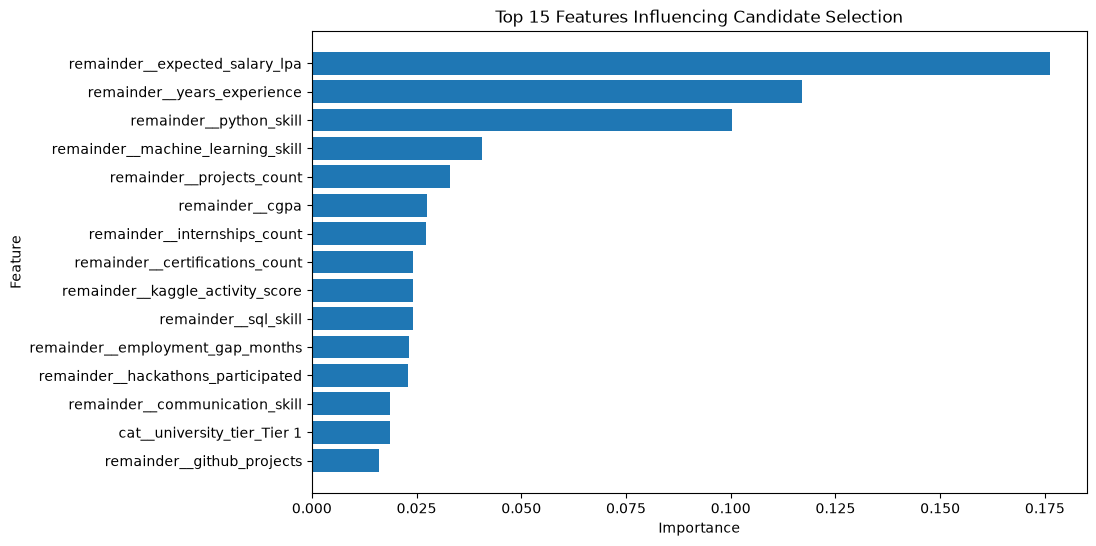

In [54]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['feature'][::-1],
    top_features['importance'][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Candidate Selection")

plt.show()

In [51]:
pip install matplotlib

  Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 1.3 MB/s eta 0:00:08
   ---- ----------------------------------- 1.0/9.5 MB 1.3 MB/s eta 0:00:07
   ----- ---------------------------------- 1.3/9.5 MB 1.4 MB/s eta 0:00:06
   ------ --------------------------------- 1.6/9.5 MB 1.4 MB/s eta 0:00:06
   -------- ------------------------------- 2.1/9.5 MB 1.5 MB/s eta 0:00:05
   ----------- ---------------------------- 2.6/9.5 MB 1.7 MB/s eta 0:00:05
   ------------ --------------------------- 2.9/9.5 MB 1.8 MB/s eta 0:00:04
   ---------------- ----------------------- 3.9/9.5 MB 1.9 MB/s eta 0:00:03
   ------------------- -------------------- 4.7/9.5 MB 2.1 MB/s eta 0:00:03
   ---------------------- ----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [56]:
baseline_results = {
    "model": "XGBoost",
    "accuracy": accuracy,
    "roc_auc": roc_auc,
    "selected_precision": 0.86,
    "selected_recall": 0.86,
    "selected_f1": 0.86
}

print(baseline_results)

{'model': 'XGBoost', 'accuracy': 0.8882, 'roc_auc': 0.9565489375, 'selected_precision': 0.86, 'selected_recall': 0.86, 'selected_f1': 0.86}


In [57]:
pip install shap

   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/43.0 MB 1.5 MB/s eta 0:00:28
    --------------------------------------- 1.0/43.0 MB 1.8 MB/s eta 0:00:23
   - -------------------------------------- 1.6/43.0 MB 1.9 MB/s eta 0:00:22
   - -------------------------------------- 2.1/43.0 MB 2.1 MB/s eta 0:00:20
   -- ------------------------------------- 2.6/43.0 MB 2.1 MB/s eta 0:00:20
   --- ------------------------------------ 3.4/43.0 MB 2.3 MB/s eta 0:00:18
   --- ------------------------------------ 4.2/43.0 MB 2.5 MB/s eta 0:00:16
   ---- ----------------------------------- 5.0/43.0 MB 2.6 MB/s eta 0:00:15
   ----- ---------------------------------- 5.8/43.0 MB 2.8 MB/s eta 0:00:14
   ------ --------------------------------- 6.8/43.0 MB 3.0 MB/s eta 0:00:13
   ------- -------------------------------- 8.1/43.0 MB 3.3 MB/s eta 0:00:11
   --------- 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
import shap

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test_encoded)

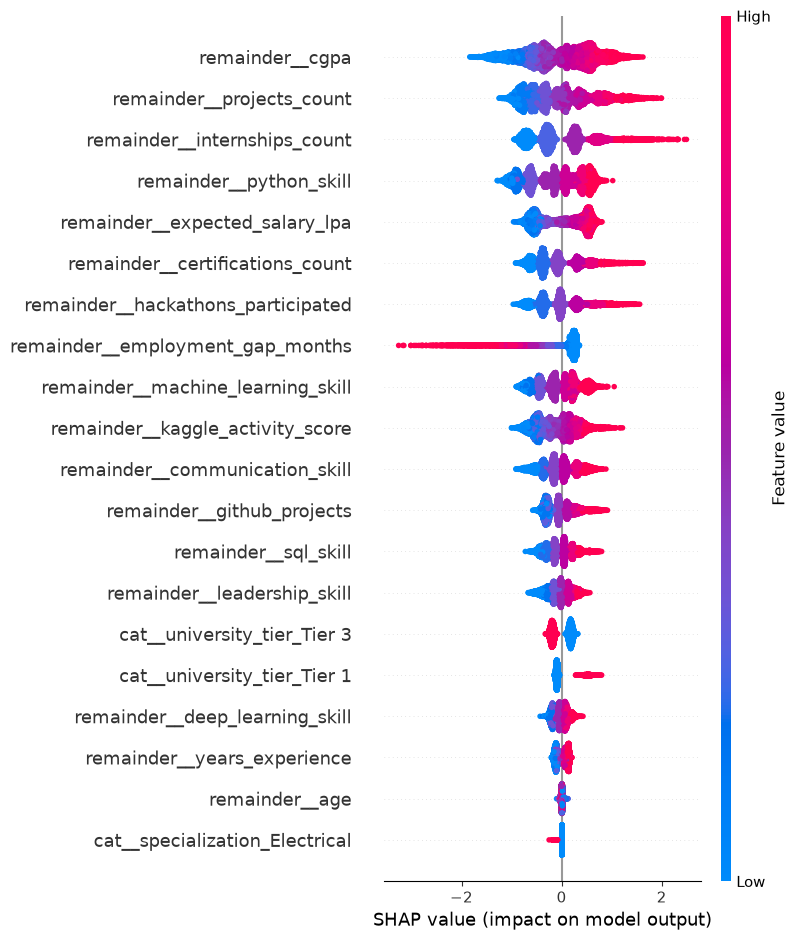

In [60]:
shap.summary_plot(
    shap_values,
    X_test_encoded,
    feature_names=preprocessor.get_feature_names_out()
)

In [61]:
from sklearn.feature_extraction.text import TfidfVectorizer

resumes = [
    "Python developer with machine learning and SQL experience",
    "Java developer with Spring Boot and SQL experience",
    "Data scientist with Python machine learning deep learning",
    "Frontend developer with React JavaScript and CSS"
]

In [62]:
tfidf = TfidfVectorizer()

X_text = tfidf.fit_transform(resumes)

In [64]:
print(tfidf.get_feature_names_out())

['and' 'boot' 'css' 'data' 'deep' 'developer' 'experience' 'frontend'
 'java' 'javascript' 'learning' 'machine' 'python' 'react' 'scientist'
 'spring' 'sql' 'with']


In [66]:
print(X_text.toarray())

[[0.31163393 0.         0.         0.         0.         0.31163393
  0.3849299  0.         0.         0.         0.3849299  0.3849299
  0.3849299  0.         0.         0.         0.3849299  0.25478116]
 [0.27646439 0.43313489 0.         0.         0.         0.27646439
  0.34148853 0.         0.43313489 0.         0.         0.
  0.         0.         0.         0.43313489 0.34148853 0.22602776]
 [0.         0.         0.         0.37791387 0.37791387 0.
  0.         0.         0.         0.         0.59590328 0.29795164
  0.29795164 0.         0.37791387 0.         0.         0.19721114]
 [0.2829953  0.         0.44336682 0.         0.         0.2829953
  0.         0.44336682 0.         0.44336682 0.         0.
  0.         0.44336682 0.         0.         0.         0.2313672 ]]


In [68]:
import re

def clean_resume_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

In [70]:
sample_resume = """
PYTHON Developer!!!
Experience in Machine Learning, SQL & Data Analysis.
"""

cleaned_resume = clean_resume_text(sample_resume)

print("Original:")
print(sample_resume)

print("\nCleaned:")
print(cleaned_resume)

Original:

PYTHON Developer!!!
Experience in Machine Learning, SQL & Data Analysis.


Cleaned:
python developer experience in machine learning sql data analysis


In [74]:
cleaned_resumes = [clean_resume_text(resume) for resume in resumes]

for i, resume in enumerate(cleaned_resumes, start=1):
    print(f"Resume {i}:")
    print(resume)
    print()

Resume 1:
python developer with machine learning and sql experience

Resume 2:
java developer with spring boot and sql experience

Resume 3:
data scientist with python machine learning deep learning

Resume 4:
frontend developer with react javascript and css



In [76]:
[clean_resume_text(resume) for resume in resumes]

['python developer with machine learning and sql experience',
 'java developer with spring boot and sql experience',
 'data scientist with python machine learning deep learning',
 'frontend developer with react javascript and css']

In [78]:
tfidf = TfidfVectorizer()

X_text = tfidf.fit_transform(cleaned_resumes)

print("TF-IDF shape:", X_text.shape)

TF-IDF shape: (4, 18)


In [80]:
print("Number of features:", len(tfidf.get_feature_names_out()))

Number of features: 18


In [82]:
print("Features:")
print(tfidf.get_feature_names_out())

Features:
['and' 'boot' 'css' 'data' 'deep' 'developer' 'experience' 'frontend'
 'java' 'javascript' 'learning' 'machine' 'python' 'react' 'scientist'
 'spring' 'sql' 'with']


In [84]:
skill_list = [
    "python",
    "java",
    "sql",
    "machine learning",
    "deep learning",
    "react",
    "javascript",
    "css",
    "spring boot",
    "data analysis",
    "frontend",
    "backend",
    "mongodb",
    "fastapi",
    "docker",
    "aws"
]

In [86]:
def extract_skills(text, skill_list):
    text = text.lower()
    
    found_skills = []

    for skill in skill_list:
        if skill in text:
            found_skills.append(skill)

    return found_skills

In [88]:
for i, resume in enumerate(cleaned_resumes, start=1):
    skills = extract_skills(resume, skill_list)
    
    print(f"Resume {i} skills:")
    print(skills)
    print()

Resume 1 skills:
['python', 'sql', 'machine learning']

Resume 2 skills:
['java', 'sql', 'spring boot']

Resume 3 skills:
['python', 'machine learning', 'deep learning']

Resume 4 skills:
['java', 'react', 'javascript', 'css', 'frontend']



In [90]:
import re

def extract_skills(text, skill_list):
    text = text.lower()

    found_skills = []

    for skill in skill_list:
        pattern = r'\b' + re.escape(skill) + r'\b'

        if re.search(pattern, text):
            found_skills.append(skill)

    return found_skills

In [92]:
for i, resume in enumerate(cleaned_resumes, start=1):
    skills = extract_skills(resume, skill_list)

    print(f"Resume {i} skills:")
    print(skills)
    print()

Resume 1 skills:
['python', 'sql', 'machine learning']

Resume 2 skills:
['java', 'sql', 'spring boot']

Resume 3 skills:
['python', 'machine learning', 'deep learning']

Resume 4 skills:
['react', 'javascript', 'css', 'frontend']



In [94]:
import pandas as pd

skill_features = []

for resume in cleaned_resumes:
    skills = extract_skills(resume, skill_list)

    row = []

    for skill in skill_list:
        if skill in skills:
            row.append(1)
        else:
            row.append(0)

    skill_features.append(row)

In [96]:
skill_df = pd.DataFrame(
    skill_features,
    columns=skill_list
)

print(skill_df)

   python  java  sql  machine learning  deep learning  react  javascript  css  \
0       1     0    1                 1              0      0           0    0   
1       0     1    1                 0              0      0           0    0   
2       1     0    0                 1              1      0           0    0   
3       0     0    0                 0              0      1           1    1   

   spring boot  data analysis  frontend  backend  mongodb  fastapi  docker  \
0            0              0         0        0        0        0       0   
1            1              0         0        0        0        0       0   
2            0              0         0        0        0        0       0   
3            0              0         1        0        0        0       0   

   aws  
0    0  
1    0  
2    0  
3    0  


In [98]:
tfidf_df = pd.DataFrame(
    X_text.toarray(),
    columns=tfidf.get_feature_names_out()
)

print("TF-IDF shape:", tfidf_df.shape)

TF-IDF shape: (4, 18)


In [100]:
nlp_features = pd.concat(
    [tfidf_df, skill_df],
    axis=1
)

print("NLP feature shape:", nlp_features.shape)

NLP feature shape: (4, 34)


In [102]:
print(nlp_features.head())

        and      boot       css      data      deep  developer  experience  \
0  0.311634  0.000000  0.000000  0.000000  0.000000   0.311634    0.384930   
1  0.276464  0.433135  0.000000  0.000000  0.000000   0.276464    0.341489   
2  0.000000  0.000000  0.000000  0.377914  0.377914   0.000000    0.000000   
3  0.282995  0.000000  0.443367  0.000000  0.000000   0.282995    0.000000   

   frontend      java  javascript  ...  javascript  css  spring boot  \
0  0.000000  0.000000    0.000000  ...           0    0            0   
1  0.000000  0.433135    0.000000  ...           0    0            1   
2  0.000000  0.000000    0.000000  ...           0    0            0   
3  0.443367  0.000000    0.443367  ...           1    1            0   

   data analysis  frontend  backend  mongodb  fastapi  docker  aws  
0              0         0        0        0        0       0    0  
1              0         0        0        0        0       0    0  
2              0         0        0      

In [105]:
resume_mapping = pd.DataFrame({
    "candidate_id": [1, 2, 3, 4],
    "resume_text": resumes
})

print(resume_mapping)

   candidate_id                                        resume_text
0             1  Python developer with machine learning and SQL...
1             2  Java developer with Spring Boot and SQL experi...
2             3  Data scientist with Python machine learning de...
3             4   Frontend developer with React JavaScript and CSS


In [107]:
sample_candidates = df_selection[
    df_selection["candidate_id"].isin([1, 2, 3, 4])
].copy()

sample_candidates = sample_candidates.merge(
    resume_mapping,
    on="candidate_id",
    how="left"
)

print(sample_candidates[["candidate_id", "resume_text", "selected"]])

Empty DataFrame
Columns: [candidate_id, resume_text, selected]
Index: []


In [110]:
print(df_selection["candidate_id"].head(10))
print(df_selection["candidate_id"].min())
print(df_selection["candidate_id"].max())

0    CAND-000001
1    CAND-000002
2    CAND-000003
3    CAND-000004
4    CAND-000005
5    CAND-000006
6    CAND-000007
7    CAND-000008
8    CAND-000009
9    CAND-000010
Name: candidate_id, dtype: str
CAND-000001
CAND-050000


In [112]:
resume_mapping = pd.DataFrame({
    "candidate_id": [
        "CAND-000001",
        "CAND-000002",
        "CAND-000003",
        "CAND-000004"
    ],
    "resume_text": resumes
})

print(resume_mapping)

  candidate_id                                        resume_text
0  CAND-000001  Python developer with machine learning and SQL...
1  CAND-000002  Java developer with Spring Boot and SQL experi...
2  CAND-000003  Data scientist with Python machine learning de...
3  CAND-000004   Frontend developer with React JavaScript and CSS


In [114]:
sample_candidates = df_selection[
    df_selection["candidate_id"].isin(resume_mapping["candidate_id"])
].copy()

sample_candidates = sample_candidates.merge(
    resume_mapping,
    on="candidate_id",
    how="left"
)

print(sample_candidates[[
    "candidate_id",
    "resume_text",
    "selected"
]])

  candidate_id                                        resume_text selected
0  CAND-000001  Python developer with machine learning and SQL...       No
1  CAND-000002  Java developer with Spring Boot and SQL experi...       No
2  CAND-000003  Data scientist with Python machine learning de...      Yes
3  CAND-000004   Frontend developer with React JavaScript and CSS      Yes


In [116]:
sample_resumes = sample_candidates["resume_text"].tolist()

cleaned_sample_resumes = [
    clean_resume_text(resume)
    for resume in sample_resumes
]

sample_tfidf = tfidf.transform(cleaned_sample_resumes)

sample_tfidf_df = pd.DataFrame(
    sample_tfidf.toarray(),
    columns=tfidf.get_feature_names_out()
)

print("Sample TF-IDF shape:", sample_tfidf_df.shape)

Sample TF-IDF shape: (4, 18)


In [118]:
sample_skill_features = []

for resume in cleaned_sample_resumes:
    skills = extract_skills(resume, skill_list)

    row = []

    for skill in skill_list:
        if skill in skills:
            row.append(1)
        else:
            row.append(0)

    sample_skill_features.append(row)

sample_skill_df = pd.DataFrame(
    sample_skill_features,
    columns=skill_list
)

print("Sample skill feature shape:", sample_skill_df.shape)
print(sample_skill_df)

Sample skill feature shape: (4, 16)
   python  java  sql  machine learning  deep learning  react  javascript  css  \
0       1     0    1                 1              0      0           0    0   
1       0     1    1                 0              0      0           0    0   
2       1     0    0                 1              1      0           0    0   
3       0     0    0                 0              0      1           1    1   

   spring boot  data analysis  frontend  backend  mongodb  fastapi  docker  \
0            0              0         0        0        0        0       0   
1            1              0         0        0        0        0       0   
2            0              0         0        0        0        0       0   
3            0              0         1        0        0        0       0   

   aws  
0    0  
1    0  
2    0  
3    0  


In [120]:
sample_nlp_features = pd.concat(
    [sample_tfidf_df, sample_skill_df],
    axis=1
)

print("Sample NLP feature shape:", sample_nlp_features.shape)
print(sample_nlp_features.head())

Sample NLP feature shape: (4, 34)
        and      boot       css      data      deep  developer  experience  \
0  0.311634  0.000000  0.000000  0.000000  0.000000   0.311634    0.384930   
1  0.276464  0.433135  0.000000  0.000000  0.000000   0.276464    0.341489   
2  0.000000  0.000000  0.000000  0.377914  0.377914   0.000000    0.000000   
3  0.282995  0.000000  0.443367  0.000000  0.000000   0.282995    0.000000   

   frontend      java  javascript  ...  javascript  css  spring boot  \
0  0.000000  0.000000    0.000000  ...           0    0            0   
1  0.000000  0.433135    0.000000  ...           0    0            1   
2  0.000000  0.000000    0.000000  ...           0    0            0   
3  0.443367  0.000000    0.443367  ...           1    1            0   

   data analysis  frontend  backend  mongodb  fastapi  docker  aws  
0              0         0        0        0        0       0    0  
1              0         0        0        0        0       0    0  
2      

In [122]:
sample_tfidf_df.columns = [
    f"tfidf_{col}"
    for col in sample_tfidf_df.columns
]

sample_skill_df.columns = [
    f"skill_{col.replace(' ', '_')}"
    for col in sample_skill_df.columns
]

sample_nlp_features = pd.concat(
    [sample_tfidf_df, sample_skill_df],
    axis=1
)

print("Sample NLP feature shape:", sample_nlp_features.shape)
print(sample_nlp_features.columns.tolist())

Sample NLP feature shape: (4, 34)
['tfidf_tfidf_and', 'tfidf_tfidf_boot', 'tfidf_tfidf_css', 'tfidf_tfidf_data', 'tfidf_tfidf_deep', 'tfidf_tfidf_developer', 'tfidf_tfidf_experience', 'tfidf_tfidf_frontend', 'tfidf_tfidf_java', 'tfidf_tfidf_javascript', 'tfidf_tfidf_learning', 'tfidf_tfidf_machine', 'tfidf_tfidf_python', 'tfidf_tfidf_react', 'tfidf_tfidf_scientist', 'tfidf_tfidf_spring', 'tfidf_tfidf_sql', 'tfidf_tfidf_with', 'skill_skill_python', 'skill_skill_java', 'skill_skill_sql', 'skill_skill_machine_learning', 'skill_skill_deep_learning', 'skill_skill_react', 'skill_skill_javascript', 'skill_skill_css', 'skill_skill_spring_boot', 'skill_skill_data_analysis', 'skill_skill_frontend', 'skill_skill_backend', 'skill_skill_mongodb', 'skill_skill_fastapi', 'skill_skill_docker', 'skill_skill_aws']


NameError: name 'df_selection' is not defined

In [3]:
import pandas as pd

df_selection = pd.read_csv(
    "../datasets/raw/resume_screening_dataset.csv"
)

print(df_selection.head())
print("\nShape:", df_selection.shape)
print("\nColumns:")
print(df_selection.columns)

print("\nInfo:")
print(df_selection.info())

  candidate_id  age  gender  degree          specialization university_tier  \
0  CAND-000001   24  Female  B.Tech  Information Technology          Tier 3   
1  CAND-000002   37    Male    B.E.              Mechanical          Tier 2   
2  CAND-000003   32  Female    Ph.D  Information Technology          Tier 1   
3  CAND-000004   28    Male    B.E.            Data Science          Tier 3   
4  CAND-000005   25  Female    B.E.      Business Analytics          Tier 1   

   cgpa  years_experience  internships_count  projects_count  ...  \
0  8.75                 6                  1               2  ...   
1  7.08                14                  1               5  ...   
2  7.08                10                  0               6  ...   
3  8.28                10                  1               3  ...   
4  7.42                 4                  0               1  ...   

   deep_learning_skill  communication_skill  leadership_skill  \
0                    7                    6  

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

# =========================================================
# 1. Create validation set from the existing training set
# =========================================================

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_encoded,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training shape:", X_tr.shape)
print("Validation shape:", X_val.shape)


# =========================================================
# 2. Create models
# =========================================================

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
}


# =========================================================
# 3. Evaluation function
# =========================================================

def evaluate_model(model_name, model):

    model.fit(X_tr, y_tr)

    predictions = model.predict(X_val)

    probabilities = model.predict_proba(X_val)[:, 1]

    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(y_val, predictions),
        "recall": recall_score(y_val, predictions),
        "f1": f1_score(y_val, predictions),
        "roc_auc": roc_auc_score(y_val, probabilities)
    }

    return result, model


# =========================================================
# 4. Train and compare models
# =========================================================

comparison_results = []
trained_models = {}

for model_name, model in models.items():

    result, trained_model = evaluate_model(
        model_name,
        model
    )

    comparison_results.append(result)
    trained_models[model_name] = trained_model


# =========================================================
# 5. Create comparison table
# =========================================================

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by=["f1", "roc_auc"],
    ascending=False
)

print("\nMODEL COMPARISON")
print(comparison_df.to_string(index=False))

NameError: name 'X_train_encoded' is not defined

In [8]:
import pandas as pd

from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split


# =========================================================
# 1. Separate features and target
# =========================================================

X = df_selection.drop(
    columns=["selected", "candidate_id"]
)

y = df_selection["selected"]


# =========================================================
# 2. Encode target: No = 0, Yes = 1
# =========================================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("Target mapping:")
print(dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))


# =========================================================
# 3. Identify categorical and numerical columns
# =========================================================

categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("\nCategorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)


# =========================================================
# 4. Split BEFORE encoding
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTrain shape:", X_train.shape)
print("Test shape:", X_test.shape)


# =========================================================
# 5. Create preprocessing pipeline
# =========================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ],
    remainder="passthrough"
)


# =========================================================
# 6. Fit ONLY on training data
# =========================================================

X_train_encoded = preprocessor.fit_transform(X_train)

X_test_encoded = preprocessor.transform(X_test)


print("\nEncoded train shape:", X_train_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)

Target mapping:
{'No': np.int64(0), 'Yes': np.int64(1)}

Categorical columns:
['gender', 'degree', 'specialization', 'university_tier', 'location']

Numerical columns:
['age', 'cgpa', 'years_experience', 'internships_count', 'projects_count', 'certifications_count', 'python_skill', 'sql_skill', 'machine_learning_skill', 'deep_learning_skill', 'communication_skill', 'leadership_skill', 'github_projects', 'kaggle_activity_score', 'hackathons_participated', 'expected_salary_lpa', 'employment_gap_months']

Train shape: (40000, 22)
Test shape: (10000, 22)

Encoded train shape: (40000, 70)
Encoded test shape: (10000, 70)


C:\Users\pramo\AppData\Local\Temp\ipykernel_17624\3742742787.py:35: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)


# =========================================================
# 1. Create validation set
# =========================================================

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_encoded,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training shape:", X_tr.shape)
print("Validation shape:", X_val.shape)


# =========================================================
# 2. Models
# =========================================================

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
}


# =========================================================
# 3. Evaluation function
# =========================================================

def evaluate_model(model_name, model):

    model.fit(X_tr, y_tr)

    predictions = model.predict(X_val)

    probabilities = model.predict_proba(X_val)[:, 1]

    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(y_val, predictions),
        "recall": recall_score(y_val, predictions),
        "f1": f1_score(y_val, predictions),
        "roc_auc": roc_auc_score(y_val, probabilities)
    }

    return result, model


# =========================================================
# 4. Train models
# =========================================================

comparison_results = []
trained_models = {}

for model_name, model in models.items():

    result, trained_model = evaluate_model(
        model_name,
        model
    )

    comparison_results.append(result)
    trained_models[model_name] = trained_model


# =========================================================
# 5. Comparison table
# =========================================================

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by=["f1", "roc_auc"],
    ascending=False
)

print("\nMODEL COMPARISON")
print(comparison_df.to_string(index=False))

Training shape: (32000, 70)
Validation shape: (8000, 70)


c:\Users\pramo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



MODEL COMPARISON
              model  accuracy  precision  recall       f1  roc_auc
Logistic Regression  0.886375   0.862844 0.85125 0.857008 0.956001
            XGBoost  0.880625   0.847846 0.85500 0.851408 0.952770
      Random Forest  0.862250   0.825574 0.83125 0.828402 0.938113


In [12]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print(X_train_encoded.shape)
print(X_test_encoded.shape)

(40000, 70)
(10000, 70)


In [14]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_encoded,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [16]:
params = [
    {"max_depth": 4, "learning_rate": 0.05},
    {"max_depth": 6, "learning_rate": 0.05},
    {"max_depth": 8, "learning_rate": 0.03}
]

tuning_results = []

for p in params:
    model = XGBClassifier(
        n_estimators=300,
        max_depth=p["max_depth"],
        learning_rate=p["learning_rate"],
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    )

    model.fit(X_tr, y_tr)

    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    tuning_results.append({
        "max_depth": p["max_depth"],
        "learning_rate": p["learning_rate"],
        "accuracy": accuracy_score(y_val, pred),
        "f1": f1_score(y_val, pred),
        "roc_auc": roc_auc_score(y_val, prob)
    })

tuning_df = pd.DataFrame(tuning_results)
print(tuning_df)

   max_depth  learning_rate  accuracy        f1   roc_auc
0          4           0.05  0.881625  0.852054  0.953379
1          6           0.05  0.881500  0.852428  0.952946
2          8           0.03  0.880250  0.850499  0.952472


In [18]:
final_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

final_model.fit(X_train_encoded, y_train)

final_pred = final_model.predict(X_test_encoded)
final_prob = final_model.predict_proba(X_test_encoded)[:, 1]

print("Accuracy:", accuracy_score(y_test, final_pred))
print("Precision:", precision_score(y_test, final_pred))
print("Recall:", recall_score(y_test, final_pred))
print("F1:", f1_score(y_test, final_pred))
print("ROC-AUC:", roc_auc_score(y_test, final_prob))

Accuracy: 0.888
Precision: 0.8592814371257484
Recall: 0.861
F1: 0.8601398601398601
ROC-AUC: 0.9570202083333333


In [20]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, final_pred))

print(classification_report(
    y_test,
    final_pred,
    target_names=["Not Selected", "Selected"]
))

[[5436  564]
 [ 556 3444]]
              precision    recall  f1-score   support

Not Selected       0.91      0.91      0.91      6000
    Selected       0.86      0.86      0.86      4000

    accuracy                           0.89     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.89      0.89      0.89     10000



In [22]:
feature_importance = pd.DataFrame({
    "feature": preprocessor.get_feature_names_out(),
    "importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print(feature_importance.head(15))

                               feature  importance
68      remainder__expected_salary_lpa    0.144123
59             remainder__python_skill    0.098024
55         remainder__years_experience    0.097069
61   remainder__machine_learning_skill    0.039060
57           remainder__projects_count    0.031900
56        remainder__internships_count    0.029980
54                     remainder__cgpa    0.025898
58     remainder__certifications_count    0.025191
69    remainder__employment_gap_months    0.025180
67  remainder__hackathons_participated    0.023814
60                remainder__sql_skill    0.023686
66    remainder__kaggle_activity_score    0.022795
30         cat__university_tier_Tier 1    0.020478
63      remainder__communication_skill    0.019090
32         cat__university_tier_Tier 3    0.017949


In [24]:
import shap

explainer = shap.TreeExplainer(final_model)

shap_values = explainer.shap_values(X_test_encoded)

print(shap_values.shape)

(10000, 70)


In [26]:
shap_summary = pd.DataFrame({
    "feature": preprocessor.get_feature_names_out(),
    "mean_abs_shap": abs(shap_values).mean(axis=0)
})

shap_summary = shap_summary.sort_values(
    by="mean_abs_shap",
    ascending=False
)

print(shap_summary.head(15))

                               feature  mean_abs_shap
57           remainder__projects_count       0.618268
54                     remainder__cgpa       0.608701
56        remainder__internships_count       0.555161
59             remainder__python_skill       0.530004
58     remainder__certifications_count       0.487552
67  remainder__hackathons_participated       0.422649
69    remainder__employment_gap_months       0.405677
61   remainder__machine_learning_skill       0.387986
68      remainder__expected_salary_lpa       0.384955
66    remainder__kaggle_activity_score       0.366587
63      remainder__communication_skill       0.350439
60                remainder__sql_skill       0.275680
65          remainder__github_projects       0.275397
64         remainder__leadership_skill       0.248312
32         cat__university_tier_Tier 3       0.211018


In [28]:
i = 0

candidate_shap = pd.DataFrame({
    "feature": preprocessor.get_feature_names_out(),
    "shap_value": shap_values[i]
})

candidate_shap["impact"] = candidate_shap["shap_value"].abs()

print(candidate_shap.sort_values(
    "impact",
    ascending=False
).head(10))

                              feature  shap_value    impact
59            remainder__python_skill    0.952226  0.952226
56       remainder__internships_count   -0.870350  0.870350
57          remainder__projects_count   -0.748625  0.748625
58    remainder__certifications_count    0.451792  0.451792
65         remainder__github_projects   -0.428651  0.428651
69   remainder__employment_gap_months    0.289174  0.289174
64        remainder__leadership_skill   -0.264305  0.264305
32        cat__university_tier_Tier 3    0.248700  0.248700
54                    remainder__cgpa    0.183562  0.183562
61  remainder__machine_learning_skill    0.147997  0.147997


In [31]:
i = 0

candidate = df_selection.loc[X_test.index[i]]

candidate_shap["direction"] = candidate_shap["shap_value"].apply(
    lambda x: "Toward Selected" if x > 0 else "Toward Not Selected"
)

print("Candidate ID:", candidate["candidate_id"])
print("Actual:", candidate["selected"])
print("Predicted:", "Selected" if final_pred[i] == 1 else "Not Selected")
print("Selection probability:", round(final_prob[i] * 100, 2), "%")

print("\nTop factors:")
print(
    candidate_shap
    .sort_values("impact", ascending=False)
    .head(10)[["feature", "shap_value", "direction"]]
)

Candidate ID: CAND-026618
Actual: No
Predicted: Not Selected
Selection probability: 30.21 %

Top factors:
                              feature  shap_value            direction
59            remainder__python_skill    0.952226      Toward Selected
56       remainder__internships_count   -0.870350  Toward Not Selected
57          remainder__projects_count   -0.748625  Toward Not Selected
58    remainder__certifications_count    0.451792      Toward Selected
65         remainder__github_projects   -0.428651  Toward Not Selected
69   remainder__employment_gap_months    0.289174      Toward Selected
64        remainder__leadership_skill   -0.264305  Toward Not Selected
32        cat__university_tier_Tier 3    0.248700      Toward Selected
54                    remainder__cgpa    0.183562      Toward Selected
61  remainder__machine_learning_skill    0.147997      Toward Selected


In [33]:
import joblib

joblib.dump(final_model, "resume_selection_model.pkl")
joblib.dump(preprocessor, "resume_preprocessor.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("Model files saved successfully.")

Model files saved successfully.


In [37]:
def predict_candidate(candidate_data):

    candidate_df = pd.DataFrame([candidate_data])

    encoded_data = preprocessor.transform(candidate_df)

    prediction = final_model.predict(encoded_data)[0]
    probability = final_model.predict_proba(encoded_data)[0][1]

    return {
    "prediction": "Selected" if prediction == 1 else "Not Selected",
    "selection_probability": round(float(probability) * 100, 2)
}

In [39]:
test_candidate = X_test.iloc[0].to_dict()

result = predict_candidate(test_candidate)

print(result)

{'prediction': 'Not Selected', 'selection_probability': 30.21}


In [41]:
pip install fastapi uvicorn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
import joblib
import os

os.makedirs("../models/final", exist_ok=True)
os.makedirs("../models/encoders", exist_ok=True)

joblib.dump(
    final_model,
    "../models/final/resume_selection_model.pkl"
)

joblib.dump(
    preprocessor,
    "../models/encoders/resume_preprocessor.pkl"
)

joblib.dump(
    label_encoder,
    "../models/encoders/label_encoder.pkl"
)

print("Final ML artifacts saved.")

Final ML artifacts saved.
